# Домашнее задание: модели классификации и оценка их качества.

Будем тренироваться обучать модели классификации и интерпретировать их качество.

Максимальный балл за задание 10 баллов

## Часть 1. Обучение моделей классификации (5 баллов). 

Поработайте с датасетом telecom_churn. Вам предстоит по характеристикам клиента предсказать, уйдет он или нет (целевая колонка - Churn). Каждый пункт задания весит 1 балл, если вы не ответили на какой-то вопрос, снимается 1/10 балла.

A . Решите задачу с помощью логистической регрессии:
- подберите значение гиперпараметров с помощью GridSearchCV
Что вы можете сказать об алгоритме? Он переобучился/недообучился/обучился как надо и вы довольны качеством?

B. Решите задачу с помощью метода опорных векторов (с kernel = 'linear'):
- подберите значение гиперпараметров с помощью GridSearchCV
Что вы можете сказать об алгоритме? Он переобучился/недообучился/обучился как надо и вы довольны качеством?

Не забудьте масштабировать данные перед применением линейных моделей.

C. Попробуйте увеличить число признаков с помощью добавления полиномиальных признаков. Также можно добавить функции от признаков вручную (те, которые вам кажутся подходящими в данной задаче).
Улучшилось ли качество алгоритма?

D. Постройте матрицу корреляций признаков. Есть ли признаки, которые практически не коррелируют с целевой переменной? Попробуйте их удалить. Есть ли пары сильно коррелирующих между собой признаков? Удалите по одному признаку из каждой пары.
Помогло ли это улучшить качество в данной задаче?

Пункты C и D можно скомбинировать для достижения наилучшего качества.

E. Сделайте мини-отчет о проведенной работе. Для этого ответьте на вопросы:
a) какой классификатор дал наилучший результат? чему равны значения метрик accuracy, f1-score и ROC-AUC? 
(Вы можете изначально разбить данные на train и test и сравнивать значения метрик на этих выборках; или же можно оценивать качество алгоритмов по кросс-валидации).

b) какие новые признаки вы добавили и какие признаки удалили?

c) удалось ли добиться того, что алгоритм не переобучился и не недообучился?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [4]:
df = pd.read_csv(r"C:\Users\montl\Downloads\telecom_churn.csv")
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


# Предобработка

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   3333 non-null   object 
 1   Account length          3333 non-null   int64  
 2   Area code               3333 non-null   int64  
 3   International plan      3333 non-null   object 
 4   Voice mail plan         3333 non-null   object 
 5   Number vmail messages   3333 non-null   int64  
 6   Total day minutes       3333 non-null   float64
 7   Total day calls         3333 non-null   int64  
 8   Total day charge        3333 non-null   float64
 9   Total eve minutes       3333 non-null   float64
 10  Total eve calls         3333 non-null   int64  
 11  Total eve charge        3333 non-null   float64
 12  Total night minutes     3333 non-null   float64
 13  Total night calls       3333 non-null   int64  
 14  Total night charge      3333 non-null   

Заменим категориальный данные

In [5]:
df['International plan'] = df['International plan'].map({'Yes': 1, 'No': 0})
df['Voice mail plan'] = df['Voice mail plan'].map({'Yes': 1, 'No': 0})
df = pd.get_dummies(df, columns=['State'], prefix='State', drop_first = 'True')

df['Churn'] = df['Churn'] * 1


df.head()

,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,...,State_SD,State_TN,State_TX,State_UT,State_VA,State_VT,State_WA,State_WI,State_WV,State_WY
0,128,415,0,1,25,265.1,110,45.07,197.4,99,...,0,0,0,0,0,0,0,0,0,0
1,107,415,0,1,26,161.6,123,27.47,195.5,103,...,0,0,0,0,0,0,0,0,0,0
2,137,415,0,0,0,243.4,114,41.38,121.2,110,...,0,0,0,0,0,0,0,0,0,0
3,84,408,1,0,0,299.4,71,50.90,61.9,88,...,0,0,0,0,0,0,0,0,0,0
4,75,415,1,0,0,166.7,113,28.34,148.3,122,...,0,0,0,0,0,0,0,0,0,0


from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
col = ['Account length', 'Area code', 'Number vmail messages', 'Total day minutes', 'Total day calls',
       'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge',
       'Total night minutes', 'Total night calls', 'Total night charge',
       'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls']

df[col] = scaler.fit_transform(df[col])
df.head()

In [5]:
#вычисление метрик
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score

def metrics(X_train, X_test, y_train, y_test, model):
    y_pr_train = model.predict(X_train)
    y_pr_test = model.predict(X_test)
    print('Accuracy на обучении:', accuracy_score(y_train, y_pr_train))
    print('Accuracy на тесте:', accuracy_score(y_test, y_pr_test))
    print('F1 на обучении:', f1_score(y_train, y_pr_train))
    print('F1 на тесте:', f1_score(y_test, y_pr_test))
    print('ROC AUC на обучении:', roc_auc_score(y_train, y_pr_train))
    print('ROC AUC на тесте:', roc_auc_score(y_test, y_pr_test))

# A) Логистическая регрессия

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

y = df['Churn']
X = df.drop('Churn', axis = 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

model = LogisticRegression(random_state=42)
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],  
    'solver': ['liblinear', 'lbfgs'],  
    'penalty': ['l1', 'l2', 'elasticnet', None]}

clf = GridSearchCV(model, param_grid)
clf.fit(X_train, y_train)

GridSearchCV(estimator=LogisticRegression(random_state=42),
             param_grid={'C': [0.01, 0.1, 1, 10, 100],
                         'penalty': ['l1', 'l2', 'elasticnet', None],
                         'solver': ['liblinear', 'lbfgs']})

In [9]:
clf.best_params_

{'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}

In [10]:
metrics(X_train, X_test, y_train, y_test, clf)

Accuracy на обучении: 0.8654093441920274
Accuracy на тесте: 0.87
F1 на обучении: 0.23786407766990292
F1 на тесте: 0.26136363636363635
ROC AUC на обучении: 0.5662886278445146
ROC AUC на тесте: 0.5745852747019609


**Вывод:** ROC AUC указывает, что модель чуть лучше случайного классификатора. Переобучения нет

# B) Метод опорных векторов

In [12]:
from sklearn.svm import SVC

model = SVC(kernel='rbf', random_state=42)
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'tol': [1e-3, 1e-4]}
clf = GridSearchCV(model, param_grid)
clf.fit(X_train, y_train)

GridSearchCV(estimator=SVC(random_state=42),
             param_grid={'C': [0.01, 0.1, 1, 10, 100], 'tol': [0.001, 0.0001]})

In [13]:
clf.best_params_

{'C': 10, 'tol': 0.001}

In [14]:
metrics(X_train, X_test, y_train, y_test, clf)

Accuracy на обучении: 0.9837119588512645
Accuracy на тесте: 0.873
F1 на обучении: 0.9409937888198758
F1 на тесте: 0.48995983935742965
ROC AUC на обучении: 0.9453373572208612
ROC AUC на тесте: 0.687032337557425


**Вывод:** Метрики указывают, что модель улучшилась. Но к сожалению наблюдается признаки переобучения модели

# C) Добавление полиномиальных признаков

In [11]:
from sklearn.preprocessing import PolynomialFeatures

X_2 = pd.DataFrame(PolynomialFeatures(2).fit_transform(X))
X_train, X_test, y_train, y_test = train_test_split(X_2, y, test_size = 0.3, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(random_state=42)
param_grid = {
    'C': [0.01, 0.1, 1, 10],  
    'solver': ['liblinear', 'lbfgs'],  
    'penalty': ['l1', 'l2', 'elasticnet', None]}

clf = GridSearchCV(model, param_grid)
clf.fit(X_train, y_train)

GridSearchCV(estimator=LogisticRegression(random_state=42),
             param_grid={'C': [0.01, 0.1, 1, 10],
                         'penalty': ['l1', 'l2', 'elasticnet', None],
                         'solver': ['liblinear', 'lbfgs']})

In [12]:
clf.best_params_

{'C': 0.1, 'penalty': 'l1', 'solver': 'liblinear'}

In [13]:
metrics(X_train, X_test, y_train, y_test, clf)

Accuracy на обучении: 0.9121303043291898
Accuracy на тесте: 0.879
F1 на обучении: 0.6182495344506518
F1 на тесте: 0.40394088669950745
ROC AUC на обучении: 0.7363404267878753
ROC AUC на тесте: 0.6322714624931661


**Вывод:** Лучше логрега, но уступает svm.

# Корреляционная матрица

In [15]:
df = pd.read_csv(r"C:\Users\montl\Downloads\telecom_churn.csv")

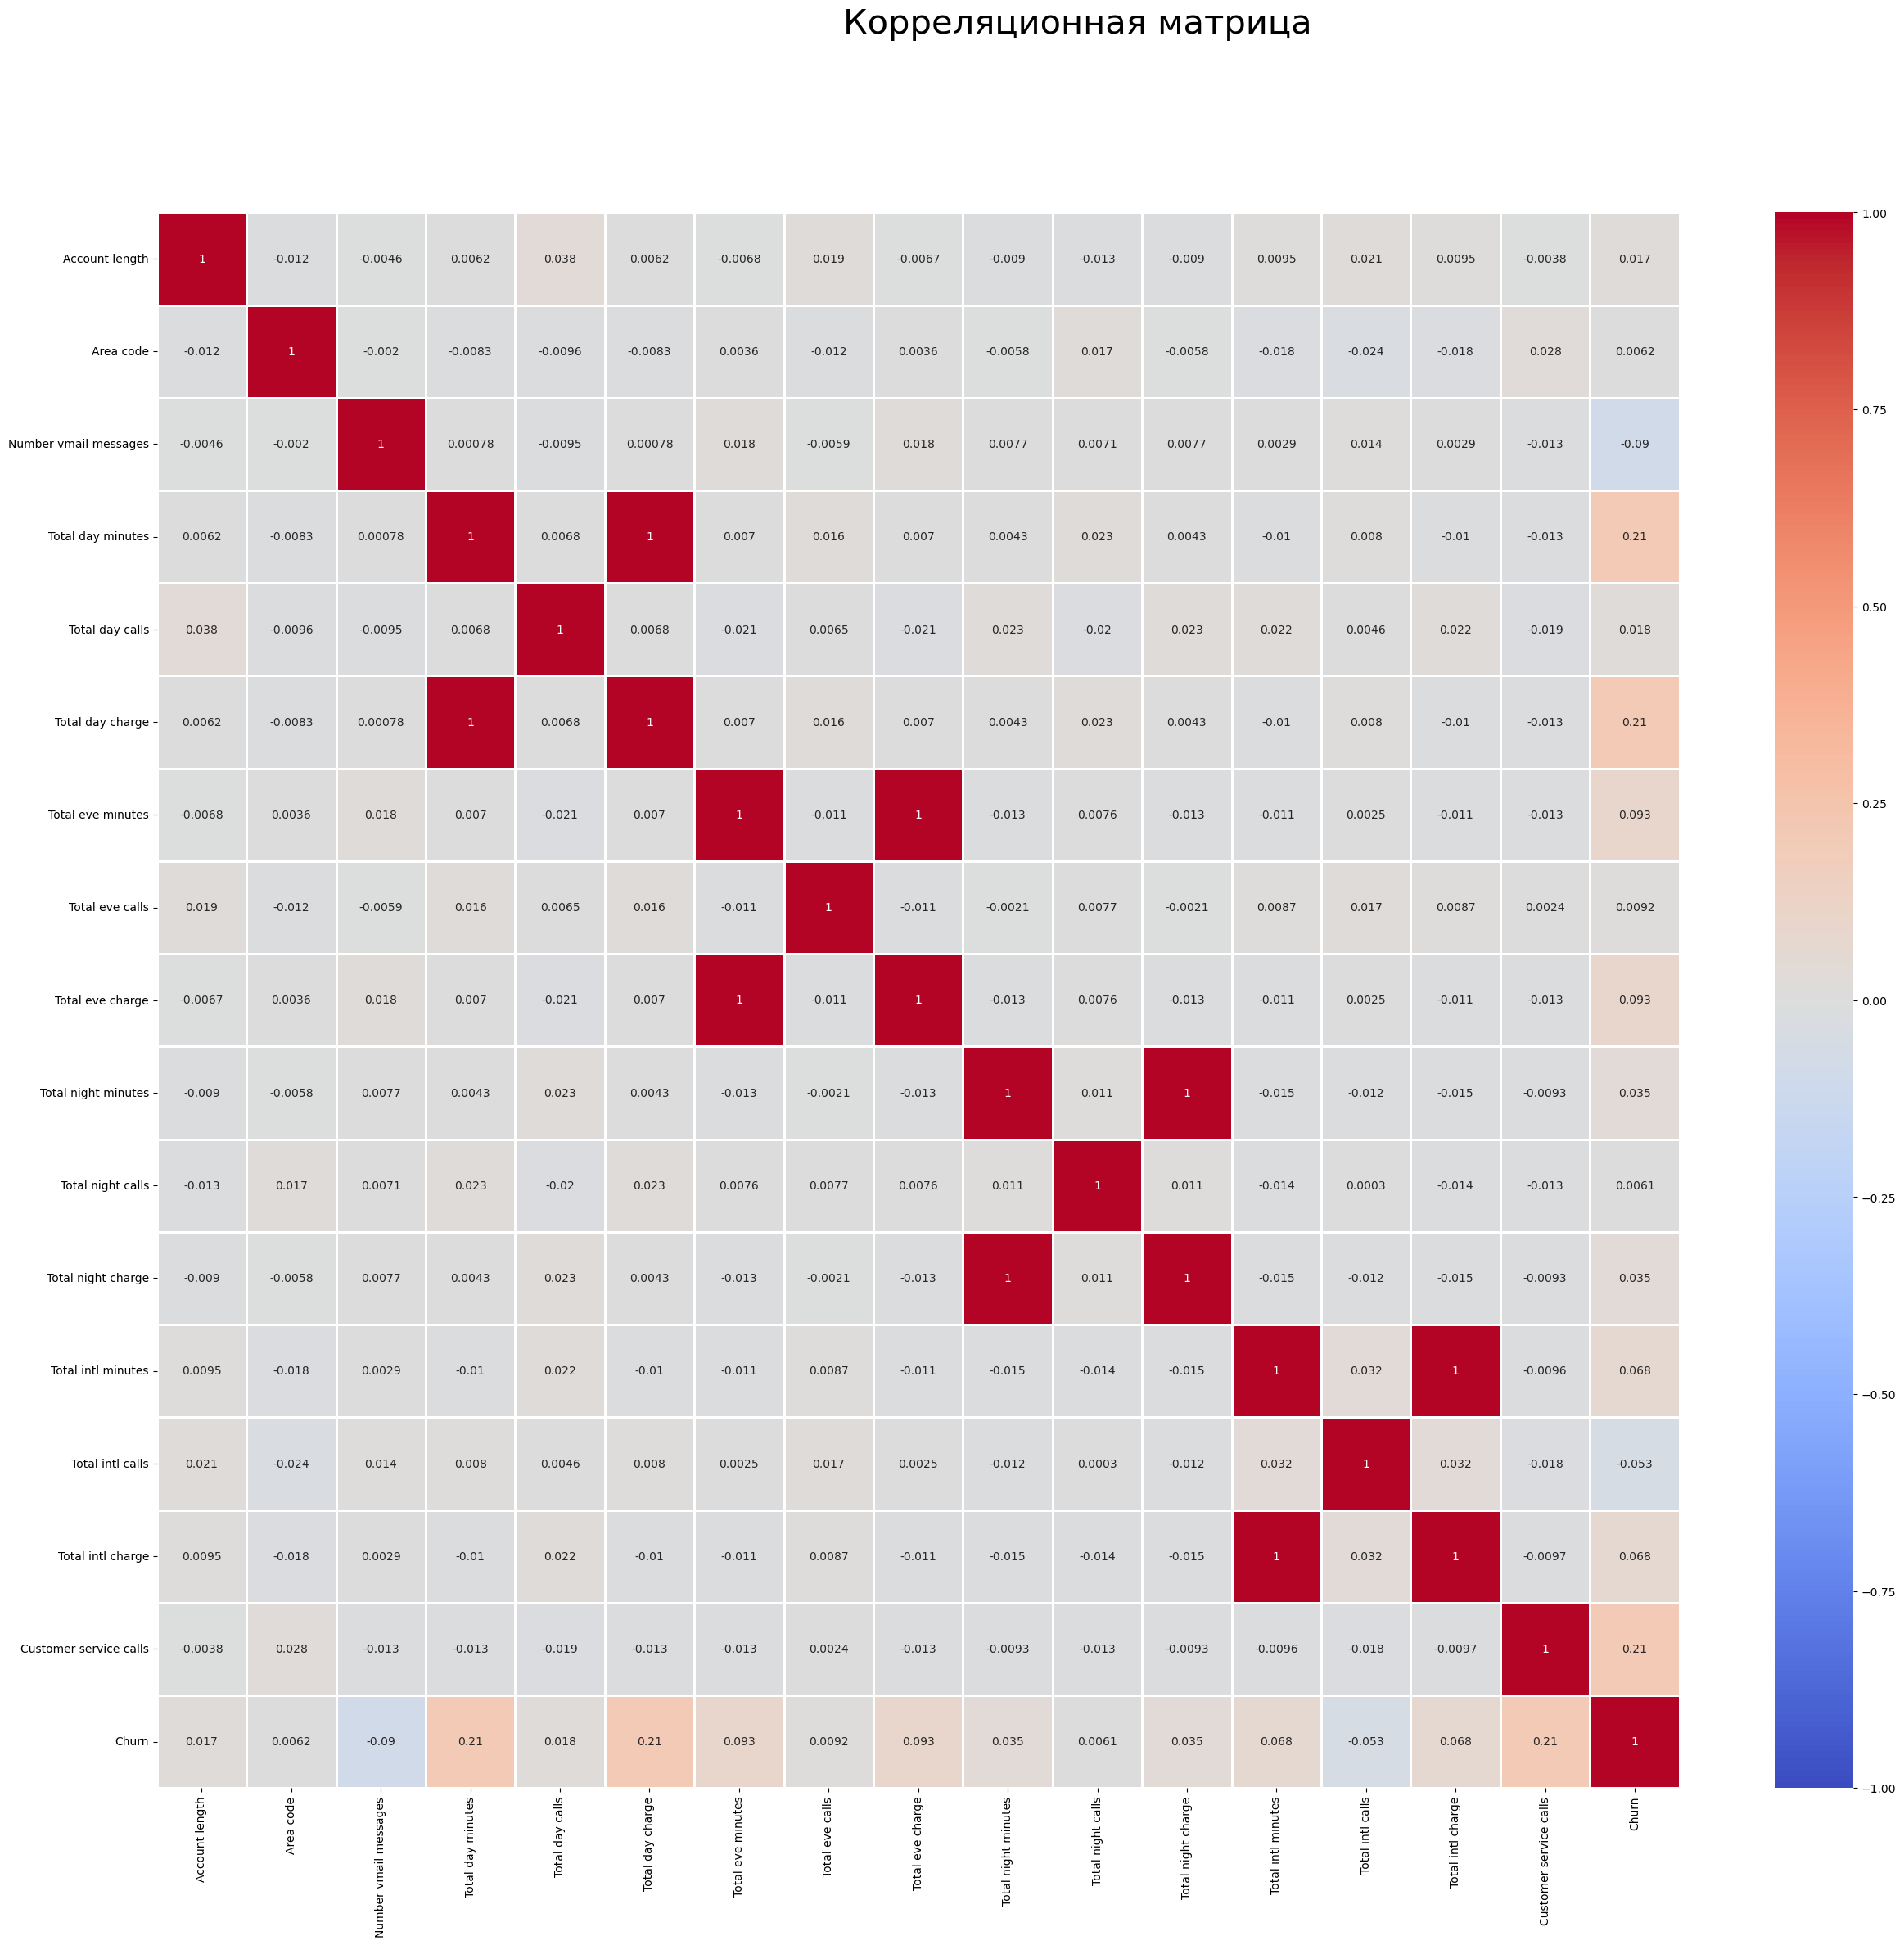

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(30, 25))
sns.heatmap(df.corr(), annot=True, linewidth=.9, vmin = -1, cmap='coolwarm')

fig.suptitle("Корреляционная матрица", fontsize=30);

In [26]:
df.drop(columns=['Area code', 'Total day calls', 'Total night calls', 'Total eve calls'], inplace=True)
X_2 = pd.DataFrame(PolynomialFeatures(2).fit_transform(X))
X_train, X_test, y_train, y_test = train_test_split(X_2, y, test_size = 0.3, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(random_state=42)
param_grid = {
    'C': [0.01, 0.1, 1, 10],  
    'solver': ['liblinear', 'lbfgs'],  
    'penalty': ['l1', 'l2', 'elasticnet', None]}

clf = GridSearchCV(model, param_grid)
clf.fit(X_train, y_train)

GridSearchCV(estimator=LogisticRegression(random_state=42),
             param_grid={'C': [0.01, 0.1, 1, 10],
                         'penalty': ['l1', 'l2', 'elasticnet', None],
                         'solver': ['liblinear', 'lbfgs']})

In [27]:
clf.best_params_

{'C': 0.1, 'penalty': 'l1', 'solver': 'liblinear'}

In [28]:
metrics(X_train, X_test, y_train, y_test, clf)

Accuracy на обучении: 0.9121303043291898
Accuracy на тесте: 0.879
F1 на обучении: 0.6182495344506518
F1 на тесте: 0.40394088669950745
ROC AUC на обучении: 0.7363404267878753
ROC AUC на тесте: 0.6322714624931661


**Вывод:** удаление некоррелируемых признаков не сыграло значения, скорре всего вина в l1 регуляризации, которая и так зануляла удаленные признаки

# Итог

**A)** SVM
Accuracy на обучении: 0.9837119588512645
Accuracy на тесте: 0.873
F1 на обучении: 0.9409937888198758
F1 на тесте: 0.48995983935742965
ROC AUC на обучении: 0.9453373572208612
ROC AUC на тесте: 0.687032337557425

**B)** Были удалены: 'Area code', 'Total day calls', 'Total night calls', 'Total eve calls'

**C)** Метрики на тесте показали результаты хуже, чем на обучающей, что говорит о переобучении

## Часть 2. Оценка качества моделей классификации (5 баллов).

В этой части вы будете работать с данными в задаче скоринга. За работу с этими данными можно получить **5 баллов.**

* Колонки 0, 1, ..., 13 - анонимизированные характеристики клиентов (некоторые числовые, некоторые категориальные). 
* Target - целевая переменная: 1 - выдать кредит, 0 - не выдать кредит.

На этих данных было обучено три различных алгоритма классификации и получены предсказания:
* pred1_probs - предсказанные вероятности положительного класса, полученные алгоритмом 1.
* pred1_classes - предсказанные алгоритмом 1 классы
* pred2_probs, pred2_classes, pred3_probs, pred3_classes - аналогичные величины для алгоритмов 2 и 3

Наша задача - оценить качество каждого из трех алгоритмов и разобраться, какой из алгоритмов лучше всего работает в данной задаче.

In [2]:
df = pd.read_csv(r"C:\Users\montl\Downloads\credit_scoring_example.csv")
df.head()

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,target,pred1_probs,pred1_classes,pred2_probs,pred2_classes,pred3_probs,pred3_classes
0,1,22.08,11.46,2,4,4,1.585,0,0,0,...,2,100,1213,0,0.506772,1,0.610853,1,0.375494,0
1,0,22.67,7.00,2,8,4,0.165,0,0,0,...,2,160,1,0,0.358519,0,0.185941,0,0.200975,0
2,0,29.58,1.75,1,4,4,1.250,0,0,0,...,2,280,1,0,0.358753,0,0.523009,1,0.160465,0
3,0,21.67,11.50,1,5,3,0.000,1,1,11,...,2,0,1,1,0.408729,0,0.185941,0,0.357771,0
4,1,20.17,8.17,2,6,4,1.960,1,1,14,...,2,60,159,1,0.480904,0,0.526646,1,0.260169,0


**Задание 1. (0.25  баллов)** Проверьте target на сбалансированность по классам, сделайте вывод.

In [3]:
df["target"].value_counts()

0    382
1    307
Name: target, dtype: int64

Таргет не сбалансирован

**Задание 2. (0.25  баллов)** Вычислите accuracy - долю правильных ответов каждого из алгоритмов. Какой алгоритм имеет наибольшую accuracy?

In [6]:
print("Accuracy pred1_classes:", accuracy_score(df["target"], df["pred1_classes"]))
print("Accuracy pred2_classes:", accuracy_score(df["target"], df["pred2_classes"]))
print("Accuracy pred3_classes:", accuracy_score(df["target"], df["pred3_classes"]))

Accuracy pred1_classes: 0.6618287373004355
Accuracy pred2_classes: 0.6719883889695211
Accuracy pred3_classes: 0.6400580551523948


Второй алгоритм имеет лучшую accuracy

**Задание 3. (0.25  баллов)** Теперь вычислите точность и полноту каждого из алгоритмов.

In [7]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

print("Accuracy pred1_classes:", precision_score(df["target"], df["pred1_classes"]))
print("Accuracy pred2_classes:", precision_score(df["target"], df["pred2_classes"]))
print("Accuracy pred3_classes:", precision_score(df["target"], df["pred3_classes"]), "\n")

print("Accuracy pred1_classes:", recall_score(df["target"], df["pred1_classes"]))
print("Accuracy pred2_classes:", recall_score(df["target"], df["pred2_classes"]))
print("Accuracy pred3_classes:", recall_score(df["target"], df["pred3_classes"]))

Accuracy pred1_classes: 0.6907216494845361
Accuracy pred2_classes: 0.6103542234332425
Accuracy pred3_classes: 0.6903225806451613 

Accuracy pred1_classes: 0.4364820846905538
Accuracy pred2_classes: 0.7296416938110749
Accuracy pred3_classes: 0.3485342019543974


Лучшая точность: **1 алгоритм**

Наибольшая полнота: **2 алгоритм**

Самым полезным инструментом в практических задачах является ***матрица ошибок***. Смотря на неё и регулируя порог, определяющий классы, мы можем достичь оптимального решения нашей задачи.

**Задание 4. (0.25  баллов)** Используя функцию plot_confusion_matrix для визуализации матрицы ошибок, нарисуйте матрицы ошибок всех трех алгоритмов.

In [8]:
import itertools
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
 
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)
 
    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")
 
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

In [9]:
cm1 = confusion_matrix(df["target"], df["pred1_classes"])
cm2 = confusion_matrix(df["target"], df["pred2_classes"])
cm3 = confusion_matrix(df["target"], df["pred3_classes"])

classes = df["target"].unique()

**1 алгоритм**

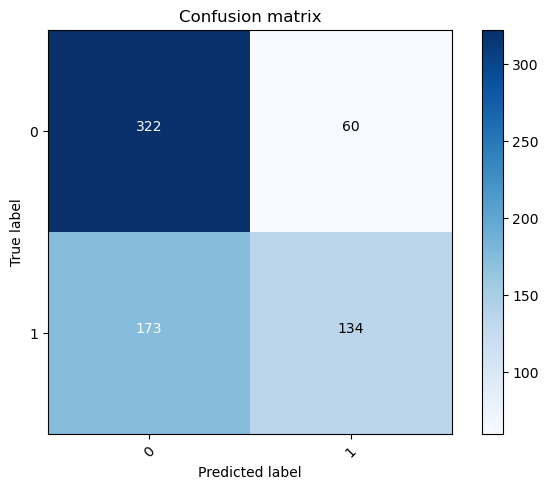

In [10]:
plot_confusion_matrix(cm1, classes)

**2 алгоритм**

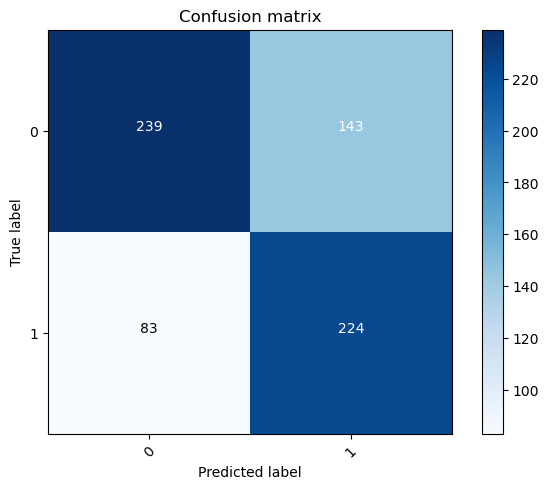

In [11]:
plot_confusion_matrix(cm2, classes)

**3 алгоритм**

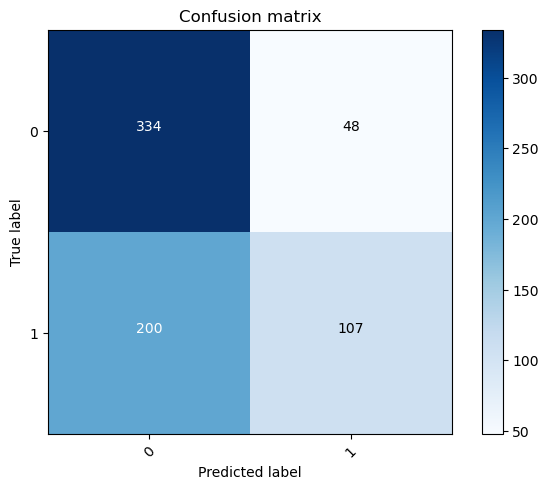

In [12]:
plot_confusion_matrix(cm3, classes)

Давайте определимся с целями нашего предсказания:
    
* **Вариант 1**: хотим выдать кредит максимальному числу людей среди тех, кто мог бы его вернуть. При этом не хотим много ошибаться (общее число ошибок не более 35%).
  
1) Мы не хотим, чтобы алгоритм много ошибался: accuracy $\geq$ 0.65.

2) Кроме того полнота должна быть как можно больше (число в левом нижнем квадрате матрицы ошибок минимально).

**Задание 5. (1  балл)** Для каждого алгоритма найдите такой порог принятия решения, чтобы выполнялись перечисленные выше условия. Какой максимальной полноты можно добиться у каждой из моделей при условии, что accuracy $\geq$ 0.65?

**Комментарий:** порог можно искать в цикле с небольшим шагом.

In [33]:
def jaba(target, proba):
    best_recall = 0
    best_i = 0
    for i in np.arange(0, 1.01, 0.01):
        pred = (proba >= i) * 1
        if (accuracy_score(target, pred) >= 0.65) & (recall_score(target, pred) > best_recall):
            best_recall = recall_score(target, pred)
            best_i = i
    return(best_i)

In [37]:
porog1 = jaba(df["target"], df["pred1_probs"])
porog2 = jaba(df["target"], df["pred2_probs"])
porog3 = jaba(df["target"], df["pred3_probs"])

print("Порог принятия решения 1 алгоритма:", porog1)
print("Порог принятия решения 2 алгоритма:", porog2)
print("Порог принятия решения 3 алгоритма:", porog3)

Порог принятия решения 1 алгоритма: 0.36
Порог принятия решения 2 алгоритма: 0.27
Порог принятия решения 3 алгоритма: 0


**Задание 6. (0.25  баллов)** Визуализируйте матрицу ошибок для каждого из трех алгоритмов с подобранным порогом.

In [36]:
prob1 = (df["pred1_probs"]>=porog1)
prob2 = (df["pred2_probs"]>=porog2)

cm1 = confusion_matrix(df["target"], prob1)
cm2 = confusion_matrix(df["target"], prob2)

**1 Алгоритм**

0.742671009771987


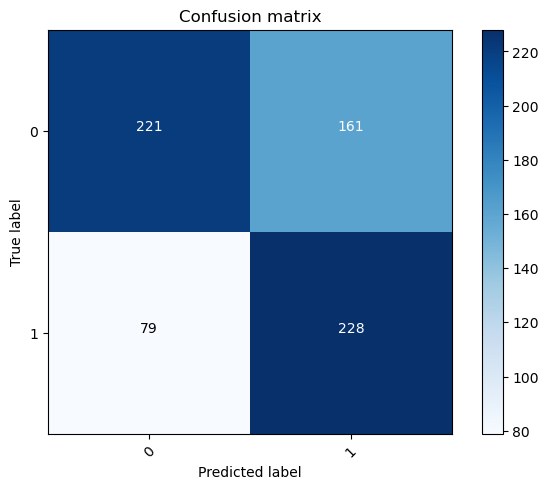

In [35]:
plot_confusion_matrix(cm1, classes)
print(recall_score(df["target"], prob1))

**2 Алгоритм**

0.8371335504885994


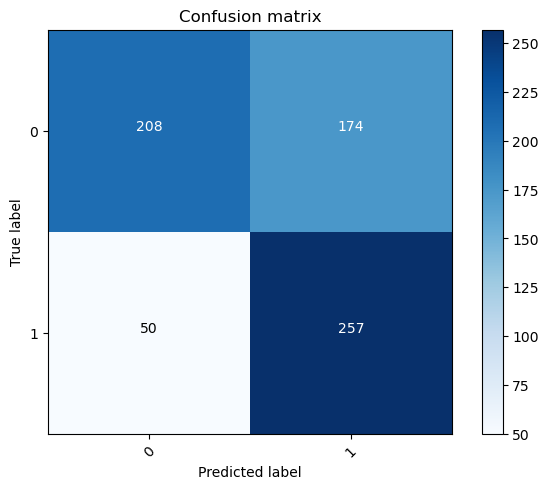

In [27]:
plot_confusion_matrix(cm2, classes)
print(recall_score(df["target"], prob2))

**Выводы:** Максимальный recall: 0.837

Второй алгоритм сработал лучше, так как его полнота больше, что и требовалось по условию

Наша цель может звучать и по-другому:
    
* **Вариант 2**: среди тех, кому модель выдает кредит, должно быть меньше всего ошибок (мало людей, кто его на самом деле не вернет - на них будем терять деньги). 
    При этом не хотим много ошибаться (общее число ошибок не более 35%).
  
1) Мы не хотим, чтобы алгоритм много ошибался: accuracy $\geq$ 0.65.

2) Кроме того точность должна быть как можно больше (число в правом верхнем квадрате матрицы ошибок минимально).

**Задание 7. (0.75  баллов)** Для каждого алгоритма найдите порог принятия решения, чтобы выполнялись перечисленные выше условия. Какой максимальной точности можно добиться у каждой из моделей при условии, что accuracy $\geq$ 0.65? 

In [30]:
def jaba2(target, proba):
    best_precision = 0
    best_i = 0
    for i in np.arange(0, 1.01, 0.01):
        pred = (proba >= i) * 1
        if (accuracy_score(target, pred) >= 0.65) & (precision_score(target, pred) > best_precision):
            best_precision = precision_score(target, pred)
            best_i = i
    return(best_i)

In [38]:
porog1 = jaba2(df["target"], df["pred1_probs"])
porog2 = jaba2(df["target"], df["pred2_probs"])
porog3 = jaba2(df["target"], df["pred3_probs"])

print("Порог принятия решения 1 алгоритма:", porog1)
print("Порог принятия решения 2 алгоритма:", porog2)
print("Порог принятия решения 3 алгоритма:", porog3)

Порог принятия решения 1 алгоритма: 0.54
Порог принятия решения 2 алгоритма: 0.73
Порог принятия решения 3 алгоритма: 0


**Задание 8. (0.5  баллов)** Нарисуйте матрицы ошибок для каждого из алгоритмов с найденными значениями порога. Какая модель лучше всех справилась с этой задачей?

In [39]:
prob1 = (df["pred1_probs"]>=porog1)
prob2 = (df["pred2_probs"]>=porog2)

cm1 = confusion_matrix(df["target"], prob1)
cm2 = confusion_matrix(df["target"], prob2)

**Алгоритм 1**

0.6618287373004355


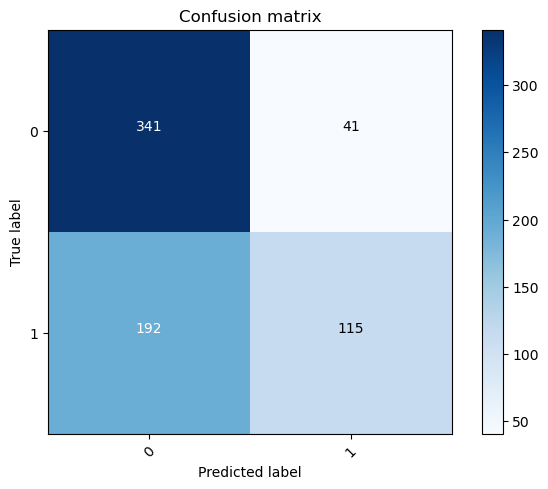

In [40]:
plot_confusion_matrix(cm1, classes)
print(accuracy_score(df["target"], prob1))

**Алгоритм 2**

0.6502177068214804


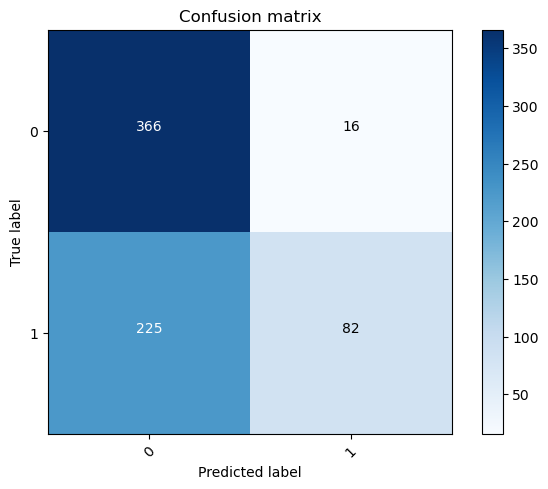

In [41]:
plot_confusion_matrix(cm2, classes)
print(accuracy_score(df["target"], prob2))

**Вывод** Максимальная точность достигается у первой модели:0.6618

В это же самое время второй алгоритм лучше, так как число в верхнем правом квадрате меньше, как требувуется по условию

Также (**Вариант 3**) можно потребовать, чтобы и точность, и полнота были высокими, то есть обе ошибки в матрице ошибок были маленькие. Как вариант - можно максимизировать F1-score (среднее гармоническое между точностью и полнотой).

**Задание 9. (0.5  баллов)** Найдите пороги для достижения максимального F1-score для каждой из трех моделей и нарисуйте матрицы ошибок. Какая модель решает поставленную задачу лучше остальных?

In [42]:
def jaba3(target, proba):
    best_f1 = 0
    best_i = 0
    for i in np.arange(0, 1.01, 0.01):
        pred = (proba >= i) * 1
        if (accuracy_score(target, pred) >= 0.65) & (f1_score(target, pred) > best_f1):
            best_f1 = f1_score(target, pred)
            best_i = i
    return(best_i)

In [43]:
porog1 = jaba3(df["target"], df["pred1_probs"])
porog2 = jaba3(df["target"], df["pred2_probs"])
porog3 = jaba3(df["target"], df["pred3_probs"])

print("Порог принятия решения 1 алгоритма:", porog1)
print("Порог принятия решения 2 алгоритма:", porog2)
print("Порог принятия решения 3 алгоритма:", porog3)

Порог принятия решения 1 алгоритма: 0.36
Порог принятия решения 2 алгоритма: 0.32
Порог принятия решения 3 алгоритма: 0


In [44]:
prob1 = (df["pred1_probs"]>=porog1)
prob2 = (df["pred2_probs"]>=porog2)

cm1 = confusion_matrix(df["target"], prob1)
cm2 = confusion_matrix(df["target"], prob2)

**Алгоритм 1**

0.6516690856313497


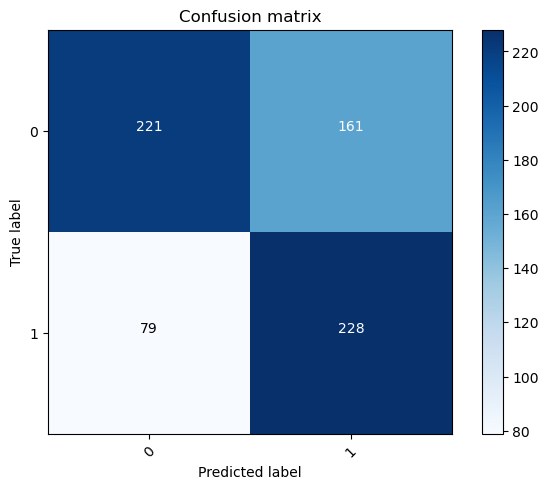

In [45]:
plot_confusion_matrix(cm1, classes)
print(accuracy_score(df["target"], prob1))

**Алгоритм 2**

0.6850507982583455


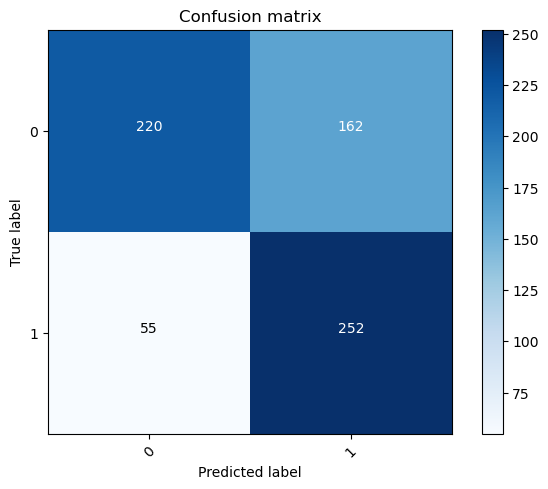

In [58]:
plot_confusion_matrix(cm2, classes)
print(accuracy_score(df["target"], prob2))

**Вывод:** В данном случае 2 алгоритм работает лучше, так как сумма левого нижнего и правого верхнего квадрата меньше, как по условию

#### Кстати

В python есть удобная функция classification_report, которая выводит значения нескольких метрик.

In [47]:
from sklearn.metrics import classification_report

print(classification_report(df['target'],df['pred1_classes']))

              precision    recall  f1-score   support

           0       0.65      0.84      0.73       382
           1       0.69      0.44      0.53       307

    accuracy                           0.66       689
   macro avg       0.67      0.64      0.63       689
weighted avg       0.67      0.66      0.65       689



### Обучим свою модель для предсказания target.

**Задание 10. (0.5  баллов)** Отнормируйте признаки в задаче и обучите логистическую регрессию предсказывать target.

In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

y = df['target']
X = df.drop(columns=['target'])

scaler = StandardScaler()
X = scaler.fit_transform(X)

model = LogisticRegression()
model.fit(X, y)
proba = model.predict_proba(X)[:,-1]

**Задание 11. (0.5  баллов)** Подберите порог для перевода предсказания в классы, чтобы максимизировать:
    а) точность 
    б) полноту 
    в) f1-score. 
Лучше ли логистическая регрессия справилась с задачей, чем три готовые модели, предсказания которых мы анализировали выше?

**А) Точность**

0.6589259796806967


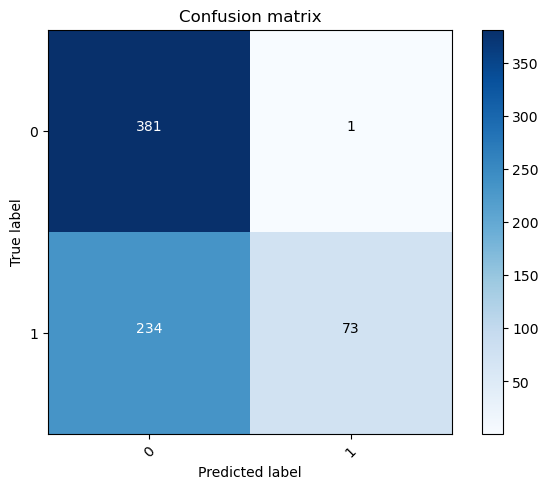

In [51]:
cut = jaba2(y, proba)
pred = (proba >= cut)

cm = confusion_matrix(y, pred)

plot_confusion_matrix(cm, classes)
print(accuracy_score(y, pred))

**Б) Полнота**

0.6502177068214804


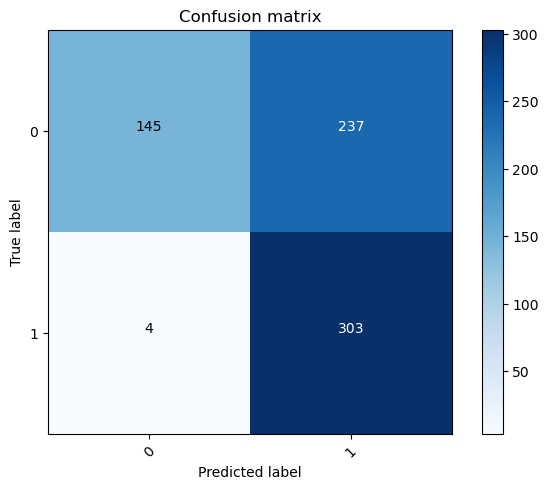

In [56]:
cut = jaba(y, proba)
pred = (proba >= cut) 

cm = confusion_matrix(y, pred)

plot_confusion_matrix(cm, classes)
print(accuracy_score(y, pred))

**В) f1-score**

0.8824383164005806


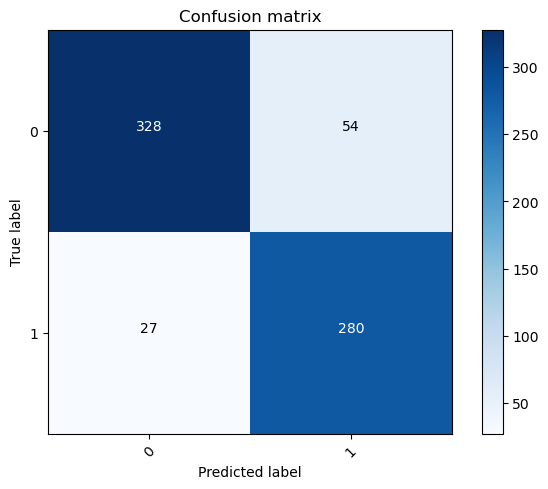

In [55]:
cut = jaba3(y, proba)

pred = (proba >= cut) 

cm = confusion_matrix(y, pred)

plot_confusion_matrix(cm, classes)
print(accuracy_score(y, pred))